In [41]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.ar_model import AutoReg

In [42]:
df = pd.read_csv('/daily-min-temperatures.csv', header=0 , parse_dates=[0])

In [43]:
df.head()

,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


In [34]:
df.head()

,Date,Temp
Date,,
1981-01-01,1981-01-01,20.7
1981-01-02,1981-01-02,17.9
1981-01-03,1981-01-03,18.8
1981-01-04,1981-01-04,14.6
1981-01-05,1981-01-05,15.8


In [44]:
df.shape

(3650, 2)

In [45]:
train, test = df.Temp[1:df.shape[0]-7], df.Temp[df.shape[0]-7:]

In [46]:
train.head()

,Temp
1,17.9
2,18.8
3,14.6
4,15.8
5,15.8


In [47]:
test.head()

,Temp
3643,12.9
3644,14.6
3645,14.0
3646,13.6
3647,13.5


In [48]:
train.dtype

dtype('float64')

In [49]:
data = train
predict =[]
for t in test:
    model = AutoReg(data,lags=1)
    model_fit = model.fit()
    y = model_fit.predict(start=len(data), end=len(train)+len(test)-1)
    print(y.values[0])
    predict.append(y.values[0])
    data = np.append(data, t)
    data = pd.Series(data)

10.464624042282537
12.508204480301929
13.825352657587116
13.36079206882315
13.05112321345733
12.973846780575858
14.678823358276793


In [50]:
predict

[np.float64(10.464624042282537),
 np.float64(12.508204480301929),
 np.float64(13.825352657587116),
 np.float64(13.36079206882315),
 np.float64(13.05112321345733),
 np.float64(12.973846780575858),
 np.float64(14.678823358276793)]

In [51]:
mse = mean_squared_error(test.values, predict)
mse

2.978033756253745

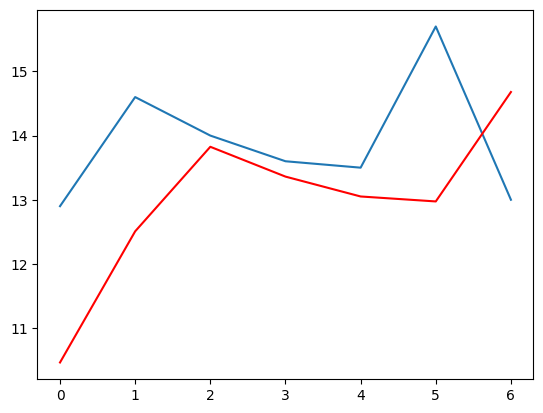

In [55]:
import matplotlib.pyplot as plt

plt.plot(test.values)
plt.plot(predict, color='red')
plt.show()